# TBATS Benchmark on M4 Hourly: smooth 1.3.0 (2026-11-05)

Rerun of the benchmark of 2026-10-06 (`2026-10-06-smooth-1-2-0-benchmark_tbats.ipynb`) on the
414 hourly series of the M4 competition, forecast 48 hours ahead with the daily (24) and weekly
(168) periods, on **smooth 1.3.0**.

**Only Python smooth is fitted**, with its default and with the normal distribution:

| Method | Call | Source |
|---|---|---|
| smooth TBATS (Python) | `TBATS(lags=[1, 24, 168]).fit(y)` | fitted here |
| smooth TBATS, dnorm (Python) | `TBATS(lags=[1, 24, 168], distribution="dnorm").fit(y)` | fitted here |
| statsforecast AutoTBATS | `AutoTBATS(season_length=[24, 168]).fit(y)` | saved, statsforecast 2.1.1 |
| forecast::tbats() | `tbats(msts(y, seasonal.periods=c(24, 168)), use.parallel=FALSE)` | saved, forecast 8.21.1 |

The two saved rows are read from `2026-10-06-benchmark-tbats-m4-hourly.csv` and are not refitted.
Their accuracy does not depend on the machine, but **their times come from another run** (4
workers on a 4-core container), so the time comparison across the two sources is only indicative.
The R implementation of smooth is not run, so this notebook says nothing about the parity at 1.3.0.

The metrics are those of the previous notebook, scored by `run_tbats_benchmark.py`: RMSSE, SAME,
the scaled pinball over the 99 levels and the coverage of each, MCE being the mean absolute
difference between the coverage and the level.

**Reproducing.** The forecasts of each series are cached in
`~/.cache/smooth-benchmarks-1-3-0/tbats-m4-hourly/`, a separate folder, because the default one
holds the forecasts of 1.2.0 and the runner resumes from what it finds. `BENCH_RERUN=1` refits
what is not cached; delete the folder to start afresh. `BENCH_WORKERS` sets the workers (30 here,
one thread each, on the AMD Ryzen 9 3950X).

In [1]:
import os

# Before the numerical libraries are imported, and before the runner reads the cache folder:
# the workers inherit both.
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS",
           "NUMBA_NUM_THREADS"):
    os.environ[_v] = "1"
os.environ["SMOOTH_BENCH_CACHE"] = os.path.expanduser("~/.cache/smooth-benchmarks-1-3-0")

import re
import subprocess
import sys
import warnings
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import run_tbats_benchmark as bench

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

DATE = "2026-11-05"
RESULTS = f"{DATE}-benchmark-tbats-m4-hourly.csv"
PREVIOUS = "2026-10-06-benchmark-tbats-m4-hourly.csv"
WORKERS = int(os.environ.get("BENCH_WORKERS", "30"))
FITTED = ["smooth", "smooth-dnorm"]
METHODS = {"smooth": "smooth TBATS (Python)", "smooth-dnorm": "smooth TBATS, dnorm (Python)",
           "statsforecast": "statsforecast AutoTBATS", "forecast": "forecast::tbats()"}
COLORS = {"smooth": "#1f77b4", "smooth-dnorm": "#9467bd", "statsforecast": "#d62728",
          "forecast": "#ff7f0e"}
LEVELS = bench.LEVELS
QS = [f"{int(round(100 * t)):02d}" for t in LEVELS]

## Versions

In [2]:
print(f"python {sys.version.split()[0]}   cores {os.cpu_count()}   workers {WORKERS}")
print(sys.executable)
for package in ("smooth", "greybox", "numpy", "pandas", "matplotlib"):
    print(f"{package:14s} {version(package)}")
print("git HEAD:", subprocess.run(["git", "log", "-1", "--format=%h %s"],
                                  capture_output=True, text=True).stdout.strip())
print("modified tracked files:", subprocess.run(["git", "status", "--porcelain", "--untracked-files=no"],
                                                capture_output=True, text=True).stdout.count("\n"))
print("forecasts in", bench.FORECASTS)

python 3.14.4   cores 32   workers 30
/home/config/Misc/Python/Libraries/openforecast-org/smooth/python/.venv/bin/python3
smooth         1.3.0
greybox        1.0.11
numpy          2.3.5
pandas         2.3.3
matplotlib     3.11.1
git HEAD: b18cda63 Merge pull request #439 from openforecast-org/code-optimisation
modified tracked files: 0
forecasts in /home/claude/.cache/smooth-benchmarks-1-3-0/tbats-m4-hourly


## Data

In [3]:
series = bench.data()
ids = list(series)
lengths = pd.Series({sid: len(x) for sid, (x, _) in series.items()})
print(f"{len(series)} series, horizon {bench.H}, periods {bench.LAGS[1:]}")
print(lengths.describe()[["min", "25%", "50%", "75%", "max"]].to_frame("in-sample length").T
      .to_string(float_format=lambda v: f"{v:.0f}"))

414 series, horizon 48, periods [24, 168]
                  min  25%  50%  75%  max
in-sample length  700  700  960  960  960


## Run or load

In [4]:
previous = pd.read_csv(PREVIOUS)
if os.environ.get("BENCH_SMOKE") == "1":
    # A test of the cells on the saved rows: nothing is fitted or written.
    results = previous[previous.method.isin(METHODS)].copy()
else:
    if os.environ.get("BENCH_RERUN", "0") == "1" or not os.path.exists(RESULTS):
        for method in FITTED:
            bench.run(method, WORKERS)
        fitted = bench.score(FITTED)
        fitted.insert(1, "version", f"smooth {version('smooth')}, greybox {version('greybox')}, "
                                    f"Python {sys.version.split()[0]}")
        saved = previous[previous.method.isin(["statsforecast", "forecast"])]
        pd.concat([fitted, saved]).to_csv(RESULTS, index=False, float_format="%.6g")
    results = pd.read_csv(RESULTS)
results["label"] = results.method.map(METHODS)
print(f"{len(results)} rows\n")
check = results.groupby("method").agg(version=("version", "first"), series=("series", "size"),
                                      failed=("rmsse", lambda v: int(v.isna().sum())))
print(check.loc[list(METHODS)].to_string())
assert all(check.series == len(series)), "a method is missing series: rerun to resume"
errors = results[results.model.astype(str).str.startswith("ERROR")]
print(f"\nerrors: {len(errors)}")
print(errors.model.value_counts().head(5).to_string() if len(errors) else "")

smooth: 414 of 414 series to forecast, 30 workers


  50/414


  100/414


  150/414


  200/414


  250/414


... (9 outputs left out)

  300/414


  350/414


  400/414


1656 rows

                                                   version  series  failed
method                                                                    
smooth         smooth 1.3.0, greybox 1.0.11, Python 3.14.4     414       0
smooth-dnorm   smooth 1.3.0, greybox 1.0.11, Python 3.14.4     414       0
statsforecast          statsforecast 2.1.1, Python 3.11.15     414       0
forecast                          forecast 8.21.1, R 4.3.3     414       0

errors: 0



## Point forecasts

In [5]:
def wide(column):
    # The metric of every method (columns) and series (rows).
    return results.pivot(index="series", columns="method", values=column).loc[ids, list(METHODS)]


def metric_table(column, label):
    values = wide(column)
    table = pd.DataFrame({"Min": values.min(), "Q1": values.quantile(0.25),
                          "Med": values.median(), "Q3": values.quantile(0.75),
                          "Max": values.max(), "Mean": values.mean(),
                          "Failed": values.isna().sum()})
    table.index = [METHODS[m] for m in table.index]
    print(f"{label}, {len(ids)} series (lower is better)")
    print(table.to_string(float_format=lambda v: f"{v:.4f}"))
    return table


rmsse_table = metric_table("rmsse", "RMSSE")

RMSSE, 414 series (lower is better)
                                Min     Q1    Med     Q3    Max   Mean  Failed
smooth TBATS (Python)        0.0671 0.2463 0.6242 1.1669 4.3235 0.8294       0
smooth TBATS, dnorm (Python) 0.0703 0.2913 0.6252 1.1727 4.5617 0.8454       0
statsforecast AutoTBATS      0.0808 0.3622 0.6876 1.2179 8.6731 1.0410       0
forecast::tbats()            0.0678 0.3279 0.6980 1.2775 7.0543 0.9094       0


In [6]:
same_table = metric_table("same", "SAME")

SAME, 414 series (lower is better)
                                Min     Q1    Med     Q3    Max   Mean  Failed
smooth TBATS (Python)        0.0014 0.0976 0.2622 0.6687 5.6389 0.5440       0
smooth TBATS, dnorm (Python) 0.0004 0.1034 0.2615 0.6685 5.6092 0.5721       0
statsforecast AutoTBATS      0.0000 0.1717 0.3432 0.8420 8.8340 0.7390       0
forecast::tbats()            0.0027 0.1525 0.3168 0.7971 7.0556 0.6370       0


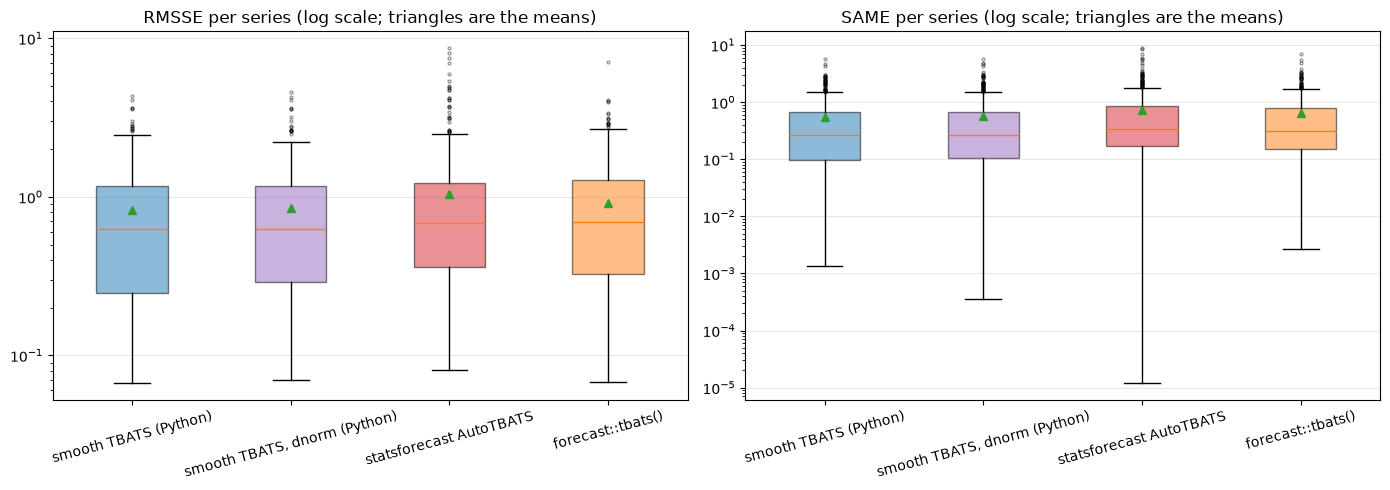

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, label in zip(axes, ("rmsse", "same"), ("RMSSE", "SAME")):
    values = wide(column)
    box = ax.boxplot([values[m].dropna() for m in METHODS], showmeans=True, patch_artist=True,
                     flierprops=dict(markersize=2, alpha=0.4))
    for patch, method in zip(box["boxes"], METHODS):
        patch.set(facecolor=COLORS[method], alpha=0.5)
    ax.set_xticks(range(1, len(METHODS) + 1), list(METHODS.values()), rotation=15)
    ax.set_yscale("log")
    ax.set_title(f"{label} per series (log scale; triangles are the means)")
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### Series by series

The share of the series where smooth (Python) is more accurate than each of the other
methods, as accurate (to 1e-8), or less accurate.

In [8]:
rows = []
for column, label in (("rmsse", "RMSSE"), ("same", "SAME"), ("pinball", "Pinball")):
    values = wide(column)
    for other in ("smooth-dnorm", "statsforecast", "forecast"):
        d = values["smooth"] - values[other]
        rows.append({"Metric": label, "Against": METHODS[other],
                     "smooth better": np.mean(d < -1e-8), "equal": np.mean(np.abs(d) <= 1e-8),
                     "smooth worse": np.mean(d > 1e-8)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.1%}"))

 Metric                      Against  smooth better  equal  smooth worse
  RMSSE smooth TBATS, dnorm (Python)          52.7%   1.2%         46.1%
  RMSSE      statsforecast AutoTBATS          62.1%   0.0%         37.9%
  RMSSE            forecast::tbats()          59.7%   0.0%         40.3%
   SAME smooth TBATS, dnorm (Python)          51.2%   1.2%         47.6%
   SAME      statsforecast AutoTBATS          61.8%   0.0%         38.2%
   SAME            forecast::tbats()          59.7%   0.0%         40.3%
Pinball smooth TBATS, dnorm (Python)          52.7%   1.2%         46.1%
Pinball      statsforecast AutoTBATS          66.9%   0.0%         33.1%
Pinball            forecast::tbats()          66.9%   0.0%         33.1%


## Predictive distribution: pinball and calibration

In [9]:
pinball = {m: results.loc[results.method == m, [f"pinball_{q}" for q in QS]].to_numpy(float)
           for m in METHODS}
coverage = {m: results.loc[results.method == m, [f"coverage_{q}" for q in QS]].to_numpy(float)
            for m in METHODS}
rows = []
for m in METHODS:
    curve = np.nanmean(coverage[m], axis=0)
    rows.append({"Method": METHODS[m],
                 "Mean pinball": np.nanmean(pinball[m]),
                 "Median pinball": np.nanmedian(np.nanmean(pinball[m], axis=1)),
                 "MCE": np.nanmean(np.abs(curve - LEVELS)),
                 "Cov@0.1": curve[9], "Cov@0.5": curve[49], "Cov@0.9": curve[89],
                 "80% interval": np.nanmean(coverage[m][:, 89] - coverage[m][:, 9]),
                 "98% interval": np.nanmean(coverage[m][:, 98] - coverage[m][:, 0])})
distribution_table = pd.DataFrame(rows)
print("Scaled pinball and calibration (lower is better for the pinball and MCE; the coverages")
print("should equal their levels, the intervals their nominal coverage)")
print(distribution_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Scaled pinball and calibration (lower is better for the pinball and MCE; the coverages
should equal their levels, the intervals their nominal coverage)
                      Method  Mean pinball  Median pinball    MCE  Cov@0.1  Cov@0.5  Cov@0.9  80% interval  98% interval
       smooth TBATS (Python)        0.3155          0.2320 0.0405   0.0962   0.4423   0.8536        0.7574        0.9617
smooth TBATS, dnorm (Python)        0.3228          0.2379 0.0509   0.0913   0.4271   0.8481        0.7568        0.9450
     statsforecast AutoTBATS        0.4078          0.2652 0.0669   0.0649   0.4026   0.8530        0.7880        0.9503
           forecast::tbats()        0.3617          0.2771 0.0825   0.0676   0.3771   0.8375        0.7699        0.9466


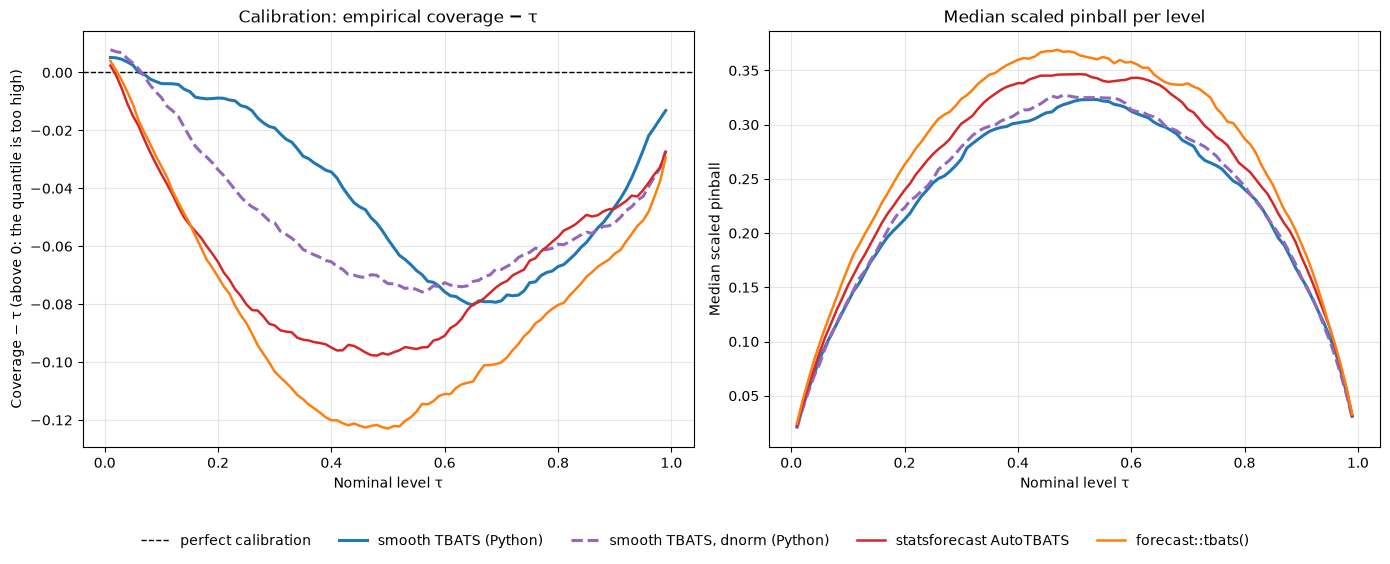

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].axhline(0.0, color="k", ls="--", lw=1, label="perfect calibration")
for m in METHODS:
    style = dict(color=COLORS[m], lw=2.2 if m.startswith("smooth") else 1.8,
                 ls={"smooth-R": ":", "smooth-dnorm": "--"}.get(m, "-"), label=METHODS[m])
    axes[0].plot(LEVELS, np.nanmean(coverage[m], axis=0) - LEVELS, **style)
    axes[1].plot(LEVELS, np.nanmedian(pinball[m], axis=0), **style)
axes[0].set(title="Calibration: empirical coverage − τ", xlabel="Nominal level τ",
            ylabel="Coverage − τ (above 0: the quantile is too high)")
axes[1].set(title="Median scaled pinball per level", xlabel="Nominal level τ",
            ylabel="Median scaled pinball")
for ax in axes:
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Time

The saved rows come from another machine and run, so their times are only indicative.

In [11]:
times = wide("time")
time_table = pd.DataFrame({"Mean, s": times.mean(), "Median, s": times.median(),
                           "Max, s": times.max(), "Total, h": times.sum() / 3600,
                           "Mean relative to smooth": times.mean() / times["smooth"].mean()})
time_table.index = [METHODS[m] for m in time_table.index]
print("Fit and forecast time per series (smooth: 30 workers; saved rows: 4 workers on 4 cores; one thread each)")
print(time_table.to_string(float_format=lambda v: f"{v:.2f}"))

Fit and forecast time per series (smooth: 30 workers; saved rows: 4 workers on 4 cores; one thread each)
                              Mean, s  Median, s  Max, s  Total, h  Mean relative to smooth
smooth TBATS (Python)           19.12      17.49   77.31      2.20                     1.00
smooth TBATS, dnorm (Python)    10.66       9.30   43.38      1.23                     0.56
statsforecast AutoTBATS         34.24      30.95  246.59      3.94                     1.79
forecast::tbats()               40.64      38.64   80.50      4.67                     2.13


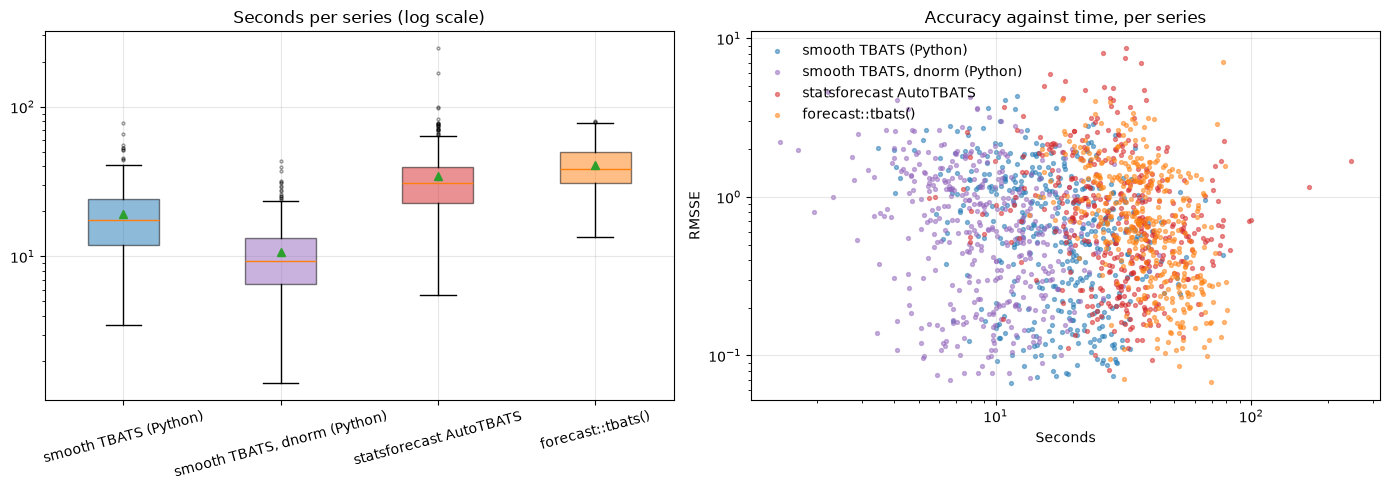

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box = axes[0].boxplot([times[m] for m in METHODS], showmeans=True, patch_artist=True,
                      flierprops=dict(markersize=2, alpha=0.4))
for patch, method in zip(box["boxes"], METHODS):
    patch.set(facecolor=COLORS[method], alpha=0.5)
axes[0].set_xticks(range(1, len(METHODS) + 1), list(METHODS.values()), rotation=15)
axes[0].set(yscale="log", title="Seconds per series (log scale)")
for m in METHODS:
    axes[1].scatter(times[m], wide("rmsse")[m], s=8, alpha=0.5, color=COLORS[m], label=METHODS[m])
axes[1].set(xscale="log", yscale="log", xlabel="Seconds", ylabel="RMSSE",
            title="Accuracy against time, per series")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Selected models

The structures in the notation of De Livera et al. (2011), TBATS(λ, {p,q}, φ,
<m₁,k₁>, ...), parsed from the model of each series: the share of series with a
Box-Cox transform (λ other than 1), with ARMA errors, with a damped trend, and the
mean number of harmonics of each period (0 when the period is dropped).

In [13]:
import re


def structure(model):
    inner = model[model.index("(") + 1:model.rindex(")")]
    tokens = [t.strip() for t in re.split(r",\s*(?![^{<]*[}>])", inner)]
    p, q = map(int, re.findall(r"\{(\d+),(\d+)\}", inner)[0])
    k = {int(m): int(n) for m, n in re.findall(r"<(\d+),(\d+)>", inner)}
    return {"Box-Cox": tokens[0] not in ("1", "-"), "ARMA": p + q > 0,
            "Damped": tokens[2] not in ("-", "trend"),
            "k(24)": k.get(24, 0), "k(168)": k.get(168, 0)}


ok = results[results.rmsse.notna()]
parsed = pd.DataFrame([structure(m) for m in ok.model], index=ok.index).assign(method=ok.method)
models_table = parsed.groupby("method").mean().loc[list(METHODS)]
models_table.index = [METHODS[m] for m in models_table.index]
print(models_table.to_string(float_format=lambda v: f"{v:.2f}"))

                              Box-Cox  ARMA  Damped  k(24)  k(168)
smooth TBATS (Python)            0.74  0.71    0.72   5.58    5.73
smooth TBATS, dnorm (Python)     0.77  0.68    0.80   5.58    5.73
statsforecast AutoTBATS          0.59  0.69    0.26   5.35    5.62
forecast::tbats()                0.60  0.83    0.36   8.54    4.08


## The distribution

The distribution that `distribution="auto"` chose for each series (the last word of
its model), and the change of the metrics against the normal distribution by the
chosen one (negative is better). For the series where the normal is chosen, the two
differ only when the structure selected with the Generalised Normal distribution is
another one.

In [14]:
def last_word(method):
    return results[results.method == method].set_index("series").model.loc[ids].str.rsplit(n=1)


chosen = last_word("smooth").str[-1]
change = pd.DataFrame({"chosen": chosen})
for column in ("rmsse", "same", "pinball"):
    change[column] = wide(column)["smooth"] - wide(column)["smooth-dnorm"]
summary = change.groupby("chosen").agg(series=("rmsse", "size"), rmsse=("rmsse", "mean"),
                                       same=("same", "mean"), pinball=("pinball", "mean"))
summary.loc["all"] = [len(change), *change[["rmsse", "same", "pinball"]].mean()]
print("Mean change against dnorm, by the chosen distribution")
print(summary.to_string(float_format=lambda v: f"{v:.4f}"))
def skeleton(model):
    # The ARMA orders, the damping and the harmonics, without the estimates
    inner = model[model.index("(") + 1:model.rindex(")")]
    tokens = [t.strip() for t in re.split(r",\s*(?![^{<]*[}>])", inner)]
    return tokens[1], tokens[2] != "-", tuple(tokens[3:])


same_structure = last_word("smooth").str[0].map(skeleton) == last_word("smooth-dnorm").str[0].map(skeleton)
print(f"\nthe same ARMA orders, damping and harmonics as with dnorm on {same_structure.mean():.1%}"
      " of the series")

Mean change against dnorm, by the chosen distribution
           series   rmsse    same  pinball
chosen                                    
dlaplace 183.0000 -0.0079 -0.0217  -0.0068
dnorm    216.0000 -0.0129 -0.0068  -0.0039
ds        15.0000 -0.1595 -0.4120  -0.0632
all      414.0000 -0.0160 -0.0281  -0.0074

the same ARMA orders, damping and harmonics as with dnorm on 57.0% of the series


## Against smooth 1.2.0

In [15]:
# The two fitted methods against their rows of smooth 1.2.0, series by series.
rows, changes = {}, []
curve_of = lambda frame: frame[[f"coverage_{q}" for q in QS]].to_numpy(float)
for m in FITTED:
    for tag, frame in (("1.2.0", previous), (version("smooth"), results)):
        part = frame[frame.method == m].set_index("series").loc[ids]
        pin = part[[f"pinball_{q}" for q in QS]].to_numpy(float)
        rows[(METHODS[m], tag)] = {
            "Median RMSSE": part.rmsse.median(), "Mean RMSSE": part.rmsse.mean(),
            "Mean SAME": part.same.mean(), "Median pinball": np.median(pin.mean(axis=1)),
            "Mean pinball": pin.mean(), "MCE": np.abs(curve_of(part).mean(axis=0) - LEVELS).mean(),
            "Time, s": part.time.mean(), "Failed": part.rmsse.isna().sum()}
    old = previous[previous.method == m].set_index("series").loc[ids]
    new = results[results.method == m].set_index("series").loc[ids]
    for column in ("rmsse", "pinball"):
        d = new[column] - old[column]
        changes.append({"Method": METHODS[m], "Metric": column.upper(), "Changed": np.mean(np.abs(d) > 1e-5),
                        "Better": np.mean(d < -1e-5), "Worse": np.mean(d > 1e-5)})
    print(f"{METHODS[m]}: the same model as 1.2.0 on {(new.model == old.model).mean():.1%} of the series")
print()
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}"))
print()
print(pd.DataFrame(changes).to_string(index=False, float_format=lambda v: f"{v:.1%}"))

smooth TBATS (Python): the same model as 1.2.0 on 100.0% of the series
smooth TBATS, dnorm (Python): the same model as 1.2.0 on 100.0% of the series

                                    Median RMSSE  Mean RMSSE  Mean SAME  Median pinball  Mean pinball   MCE  Time, s  Failed
smooth TBATS (Python)        1.2.0         0.624       0.829      0.544           0.232         0.315 0.041   20.031   0.000
                             1.3.0         0.624       0.829      0.544           0.232         0.315 0.041   19.117   0.000
smooth TBATS, dnorm (Python) 1.2.0         0.625       0.845      0.572           0.238         0.323 0.051    9.653   0.000
                             1.3.0         0.625       0.845      0.572           0.238         0.323 0.051   10.663   0.000

                      Method  Metric  Changed  Better  Worse
       smooth TBATS (Python)   RMSSE     0.0%    0.0%   0.0%
       smooth TBATS (Python) PINBALL     0.0%    0.0%   0.0%
smooth TBATS, dnorm (Python)   RMSSE     

## Nemenyi test

In [16]:
# Nemenyi at 95%: the critical distance of the mean ranks across the series.
Q95 = 2.5691     # qtukey(0.95, 4, Inf) / sqrt(2)
for column, label in (("rmsse", "RMSSE"), ("pinball", "Pinball")):
    values = wide(column).dropna()
    k, N = values.shape[1], len(values)
    cd = Q95 * np.sqrt(k * (k + 1) / (6 * N))
    ranks = values.rank(axis=1).mean().sort_values()
    print(f"{label}: {N} series, critical distance {cd:.3f}")
    print(pd.DataFrame({"Mean rank": ranks, "In the top group": ranks - ranks.iloc[0] <= cd}).to_string(
        float_format=lambda v: f"{v:.3f}"))
    print()

RMSSE: 414 series, critical distance 0.231
               Mean rank  In the top group
method                                    
smooth             2.250              True
smooth-dnorm       2.318              True
forecast           2.640             False
statsforecast      2.792             False

Pinball: 414 series, critical distance 0.231
               Mean rank  In the top group
method                                    
smooth             2.129              True
smooth-dnorm       2.221              True
forecast           2.802             False
statsforecast      2.848             False



## Findings

* **Nothing changes from smooth 1.2.0 in accuracy:** both fitted methods select the same model on all 414 series, and their RMSSE and pinball are unchanged to the stored precision (changes above 1e-5: none).
* **smooth stays ahead:** mean RMSSE 0.829 against 0.909 for forecast::tbats() and 1.041 for statsforecast, mean pinball 0.316 against 0.362 and 0.408, MCE 0.041 against 0.083 and 0.067.
* **Nemenyi:** on RMSSE and on the pinball, both smooth flavours form the top group and the two saved competitors fall outside it (critical distance 0.231).
* **Time:** 19.1 s per series with the automatic distribution and 10.7 s with the normal one, on 30 workers. The saved rows (34.2 s and 40.6 s) come from 4 workers on a 4-core container.
* No failures. R is not rerun here, so this says nothing about the parity at 1.3.0.